In [1]:
import xarray as xr
import numpy as np
import at3d
from collections import OrderedDict
import matplotlib.pyplot as plt

In [2]:
wavelength = 0.67
expr_dir = '../../dev/'
rte_grid = xr.load_dataset('{}rte_grid.nc'.format(expr_dir))

In [3]:
# Molecular Atmosphere
dropsondeFile = '../../data/CAMP2Ex_Dropsonde/CAMP2EX-dropsondes_P3B_20191002022856_R0.nc'
dropsonde = xr.load_dataset(dropsondeFile)

cond_pres = np.logical_not(np.isnan(dropsonde.pres.data))
cond_tdry = np.logical_not(np.isnan(dropsonde.tdry.data))
cond_gpsalt = np.logical_not(np.isnan(dropsonde.gpsalt.data))
cond = cond_pres & cond_tdry & cond_gpsalt

z = dropsonde.gpsalt.data[cond] / 1000
z[0] = 0 # Force bottom to be at zero

atmosphere = xr.Dataset(
    data_vars={
        'temperature': (['z'], dropsonde.tdry.data[cond] + 273.15),
        'pressure': (['z'], dropsonde.pres.data[cond])
    },
    coords={
        'z': z
    }
)

atmosphere_optical_properties = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid)


In [10]:
atmosphere_optical_properties[0.67].isel(table_index=0).legcoef

<xarray.DataArray 'legcoef' (stokes_index: 6, legendre_index: 3)>
array([[1.       , 0.       , 0.4794427],
       [0.       , 0.       , 2.876656 ],
       [0.       , 0.       , 0.       ],
       [0.       , 1.3972133, 0.       ],
       [0.       , 0.       , 1.17439  ],
       [0.       , 0.       , 0.       ]], dtype=float32)
Coordinates:
    wavelength    float64 0.67
  * stokes_index  (stokes_index) <U3 'P11' 'P22' 'P33' 'P44' 'P12' 'P34'
Dimensions without coordinates: legendre_index
Attributes:
    table_type:  vector
    units:       wavelength [micron]

In [5]:
atmosphere_optical_properties[0.67]

<xarray.Dataset>
Dimensions:        (x: 65, y: 65, z: 17, num_micro: 1, stokes_index: 6,
                    legendre_index: 3, table_index: 1)
Coordinates:
  * z              (z) float64 0.0 0.2 0.39 0.4 0.5 0.6 ... 1.3 1.4 1.41 1.6 1.8
    wavelength     float64 0.67
  * x              (x) float64 0.0 0.275 0.55 0.825 ... 16.78 17.05 17.33 17.6
  * y              (y) float64 0.0 0.275 0.55 0.825 ... 16.78 17.05 17.33 17.6
    table_index    (num_micro, x, y, z) int32 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
  * stokes_index   (stokes_index) <U3 'P11' 'P22' 'P33' 'P44' 'P12' 'P34'
Dimensions without coordinates: num_micro, legendre_index
Data variables:
    temperature    (x, y, z) float64 301.3 299.4 297.8 ... 292.4 291.1 289.6
    extinction     (x, y, z) float32 0.004909 0.004829 ... 0.004225 0.004148
    ssalb          (x, y, z) float32 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0 1.0
    phase_weights  (num_micro, x, y, z) float32 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    legcoef        (stokes_index, legendre_index, table_index) float32 1.0 .....
    delx           float64 0.275
    dely           float64 0.275
Attributes:
    units:              ['wavelength [micron]', 'temperature [K]', 'extinctio...
    wavelength_center:  0.67

In [4]:
"""
Account for the molecular atmosphere above the domain by changing the extinction in the top layer.
This algorithm ensures that the 'compensated' optical depth agrees with the 'exact' optical depth.
"""
rte_grid_exact = rte_grid.copy(deep=True)
rte_grid_exact['z'] = atmosphere.z
atmosphere_optical_properties_exact = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid_exact)
tau_exact = atmosphere_optical_properties_exact[wavelength].isel(x=0,y=0).extinction.integrate('z').data

rte_grid_minus1 = rte_grid.copy(deep=True)
rte_grid_minus1['z'] = rte_grid.z[:-1]
atmosphere_optical_properties_minus1 = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid_minus1)
tau_minus1 = atmosphere_optical_properties_minus1[wavelength].isel(x=0,y=0).extinction.integrate('z').data

del_tau = tau_exact - tau_minus1
h = rte_grid.z.data[-1] - rte_grid.z.data[-2]
xmax = atmosphere_optical_properties_minus1[wavelength].isel(x=0,y=0, z=-1).extinction.data
compensation_extinction = ((2*del_tau)/h) - xmax
atmosphere_optical_properties_comp = {}
atmosphere_optical_properties_comp[wavelength] = atmosphere_optical_properties[wavelength].copy(deep=True)
extinction = atmosphere_optical_properties[wavelength].extinction.copy(deep=True).data
extinction[:,:,-1] = compensation_extinction
atmosphere_optical_properties_comp[wavelength]['extinction'] = (['x','y','z'], extinction)

tau_exact:  0.01784
tau_comp:   0.01784
tau:        0.00814
tau minus1: 0.00730


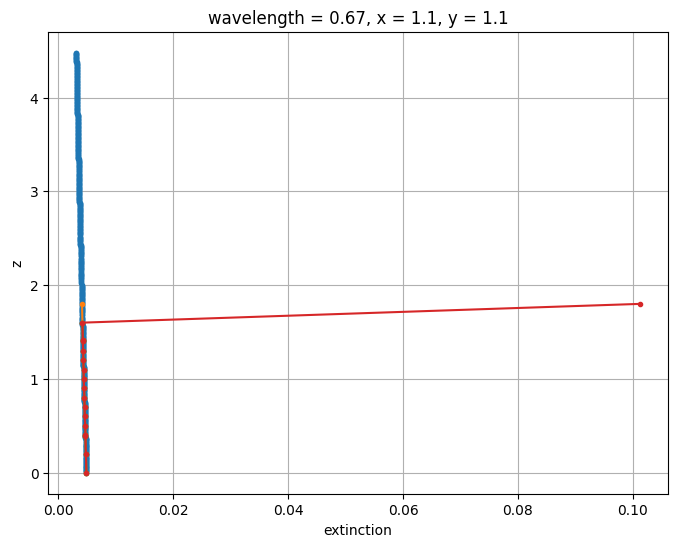

In [5]:
# PLOT CORRECTED EXTINCTION
f, ax = plt.subplots(1, 1, figsize=(8,6))
atmosphere_optical_properties_exact[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties_minus1[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties_comp[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
ax.grid()
tau_exact = atmosphere_optical_properties_exact[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau_comp = atmosphere_optical_properties_comp[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau = atmosphere_optical_properties[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau_minus1 = atmosphere_optical_properties_minus1[wavelength].isel(x=4,y=4).extinction.integrate('z').data
print('tau_exact:  {:.5f}'.format(tau_exact))
print('tau_comp:   {:.5f}'.format(tau_comp))
print('tau:        {:.5f}'.format(tau))
print('tau minus1: {:.5f}'.format(tau_minus1))

In [6]:
# Aerosols
"""
OPAC Sea salt (acc. mode) at 80% RH.
r_min = 0.009 (um)
r_max = 39.9 (um)
r_mod = 0.416 (um)
sigma = 2.03 (unitless)
rho = 1.15 (g m^-3)
m(lamda = 0.65 um) = 1.351 - 1j*1.97e-8

Notes
-----
Rho comes from Jesse's size_distr.cfg in located in 'AT3D/data/OPAC/aerosol' -- 
I can't find this parameter in the refs below.

I believe there is a couple of typos in Hess et al. (1998). First, I believe
there is a missing negative sign in front of the 1/2 within the exponential in
equation 3d. Second, I believe they are reporting the median radius - not the
mode radius as they describe in the text. This makes more sense when plotting
the distribution (eq. 3d).

(1/3/25) Aerosols above domain are not accounted for

References
----------
https://cds-espri.ipsl.upmc.fr/etherTypo/fileadmin/files/GEISA/hess-etal2.pdf
https://geisa.aeris-data.fr/opac/
"""
aerosol_mie_table = OrderedDict()
aerosol_mie_table[wavelength] = at3d.mie.get_mono_table(
    'Aerosol',
    (wavelength,wavelength),
    max_integration_radius=39.9,
    minimum_effective_radius=0.009,
    refractive_index = 1.351 - 1j*1.97e-8,
    relative_dir='../../mie_tables',
    verbose=False
)
# aerosol_mie_table[wavelength].to_netcdf('../../mie_tables/aerosol_mie_table.nc')

aerosol_optical_prop_gen = at3d.medium.OpticalPropertyGenerator(
    'aerosol',
    aerosol_mie_table,
    at3d.size_distribution.lognormal,
    particle_density=1.15,
    maxnphase=None,
    interpolation_mode='exact',
    density_normalization='geometric_extinction',
    reff=np.linspace(0.005, 8, 20),
    veff=np.linspace(0.1, 0.9, 5)
)

r_median = 0.416
S = 2.03
r_mode = np.exp(np.log(r_median) - np.log(S)**2)
reff = r_mode * np.exp((5/2)*(np.log(S)**2))
veff = np.exp(np.log(S)**2) - 1

aerosol = rte_grid.copy(deep=True)
aerosol['density'] = (['x','y','z'], np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z'])))
aerosol['reff'] = (['x','y','z'], np.ones(aerosol.density.shape) * reff)
aerosol['veff'] = (['x','y','z'], np.ones(aerosol.density.shape) * veff)
aerosol_optical_properties = aerosol_optical_prop_gen(aerosol)

hsrl_file = '../../dev/RF17_hsrl.nc'
hsrl = xr.load_dataset(hsrl_file)
hsrl = hsrl.isel(gps_time=slice(1400,2122))
hsrl['altitude'] = hsrl.altitude / 1000

## COMPENSATE FOR AEROSOLS ABOVE DOMAIN
aerosol_profile_exact = hsrl.mean('gps_time', skipna=True).ext670_532_355.copy(deep=True)
aerosol_profile_exact[np.isnan(aerosol_profile_exact.data)] = 0
tau_exact = aerosol_profile_exact.integrate('altitude').data

aerosol_profile_coarse = aerosol_profile_exact.interp(altitude=rte_grid.z.data).copy(deep=True)
aerosol_profile_minus1 = aerosol_profile_coarse.copy(deep=True).isel(altitude=slice(0,-1))
tau_minus1 = aerosol_profile_minus1.integrate('altitude').data

del_tau = tau_exact - tau_minus1
h = aerosol_profile_coarse.altitude.data[-1] - aerosol_profile_coarse.altitude.data[-2]
xmax = aerosol_profile_minus1.isel(altitude=-1).data
compensation_extinction = ((2*del_tau)/h) - xmax
aerosol_profile_comp = aerosol_profile_coarse.copy(deep=True)
aerosol_profile_comp[-1] = compensation_extinction

aerosol_extinction = np.tile(aerosol_profile_comp.data, (aerosol.dims['x'], aerosol.dims['y'], 1))
aerosol_optical_properties[wavelength]['extinction'] = (['x','y','z'], aerosol_extinction)

tau_exact:  0.17589
tau:        0.14424
tau minus1: 0.12858
tau comp:   0.17589


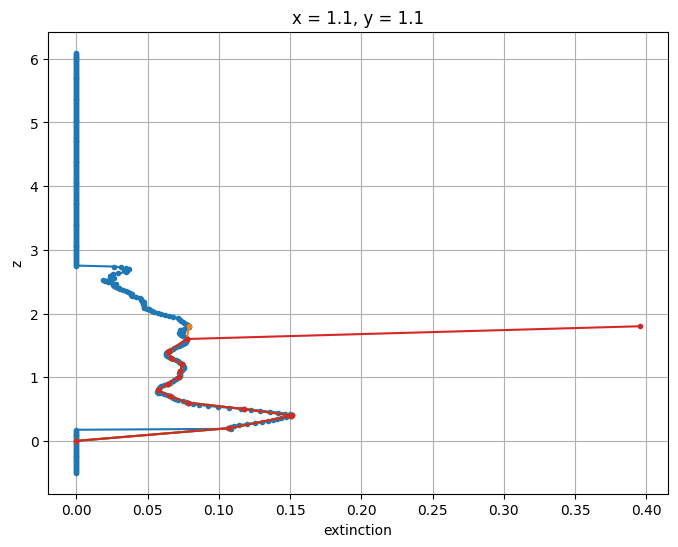

In [7]:
# PLOT CORRECTED EXTINCTION
f, ax = plt.subplots(1, 1, figsize=(8,6))
aerosol_profile_exact.plot(y='altitude', marker='.', ax=ax)
aerosol_profile_coarse.plot(y='altitude', marker='.', ax=ax)
aerosol_profile_minus1.plot(y='altitude', marker='.', ax=ax)
aerosol_optical_properties[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
ax.grid()
tau_exact = aerosol_profile_exact.integrate('altitude').data
tau = aerosol_profile_coarse.integrate('altitude').data
tau_minus1 = aerosol_profile_minus1.integrate('altitude').data
tau_comp = aerosol_profile_comp.integrate('altitude').data
print('tau_exact:  {:.5f}'.format(tau_exact))
print('tau:        {:.5f}'.format(tau))
print('tau minus1: {:.5f}'.format(tau_minus1))
print('tau comp:   {:.5f}'.format(tau_comp))

In [8]:
background_optical_scatterers = OrderedDict()
merged_properties = at3d.medium.mix_optical_properties(
    atmosphere_optical_properties_comp[wavelength],
    aerosol_optical_properties[wavelength],
    asymmetry_tol=0.02,
    maxnphase=18
)
merged_properties.to_netcdf('../../dev/atmos_aerosol_merge.nc')